In [1]:
%pylab inline 

import numpy as np

from spt3g.core import G3Units
from spt3g.maps import FlatSkyMap, HealpixSkyMap, MapProjection, flatten_pol, get_ra_dec_map
from spt3g.maps.fitsio import load_skymap_fits
from spt3g.maps.maputils import healpix_to_flatsky
from spt3g.std_processing.sourcemaps import CreateFieldMapStub

from spt3g.mapspectra.map_analysis import constructEB, mapffts_to_powerspectra
from spt3g.mapspectra.map_spectrum_classes import MapSpectrum1DDict

from spt3g.lensing.map_spec_utils import get_camb_scalcl
from spt3g.util.files import load_pickle

import sys; sys.path.append("/src/spt3g_software/scratch/cailmdaley")
from plotting import plotFrame

Populating the interactive namespace from numpy and matplotlib


# Polarization Projection & Rotation

In [ ]:
import itertools
from pathlib import Path

path = "/spt/simulation/lensing_maps/unlensed_TQU1/TQU1_planck2018_base_plikHM_TTTEEE_lowl_lowE_lensing_seed{}.fits"
def read_healpix(nside, seed):
    return {k : load_skymap_fits(path.format(seed), 
                                 memmap=True, 
                                 keys=k)[k].Rebin(8192/nside)
            for k in "QU"}
        
def project(healpix_frame, interp, rebin, proj, res_arcmin, dec_deg):
    parent = CreateFieldMapStub(res=res_arcmin*G3Units.arcmin,  proj=proj, dec_center=dec_deg)
    flatsky_frame   = {k : healpix_to_flatsky(f, map_stub=parent.Clone(False), interp=interp, rebin=rebin) 
                       for (k, f) in healpix_frame};
    
def write_flatsky_frame(flatsky_name, filename):
    frame = G3Frame()
    for k in flatsky_frame.keys():
        frame[k] = flatsky_frame[k]
    
    G3Writer(filename=filename)(frame)
    

nsides = [8192]

interps = [True]
rebins = [1]
projs = [MapProjection.ProjZEA]
resos = [2]
degs = [-57.5]
rotates = [None, 'flat']
project_options = [interps, rebins, projs, resos, degs, rotates]

seeds = range(1, 11)
path = Path("pager")
for seed, nside in itertools.product(seeds, nsides):
        healpix_frame = read_healpix(nside, seed):
        for interp, rebin, proj, res, dec, rotate in itertools.product(project_options):
            dirname = "nside={}_interp={}_rebin={}_proj={}_res={}_dec={}_rotate={}" \
                .format(nside, interp, rebin, proj, res, dec, rotate)
            filename = path / dirname / "seed_{}.g3"
            
            if filename.exists():
                print("Writing {}".format(filename))
                flatsky_frame = project(healpix_frame, interp, rebin, proj, res, dec)
                if rotate is 'flat':
                    flatten_pol(flatsky_frame.values())
                write_flatsky_frame(fllatsky_frame, str(filename))
            

All Healpix maps have `NSIDE=8192`, and all flat-sky maps have 2' resolution.   
Interpolation was used, rebinning was not.

## Current Method: Flat-sky rotation (`flatten_pol`)

Constructing a flat-sky B map from Healpix TQU goes something like this:

In [3]:
res = 2
interp = True

In [29]:
parent = CreateFieldMapStub(res=res*G3Units.arcmin,  proj=MapProjection.ProjBICEP, dec_center=0.0)

mask = np.zeros(parent.shape)
mask[50:-50, 50:-50] = 1
# mask = load_pickle("/spt/user/ddutcher/masks/3band_res2_bundle_apod_mask.pkl")

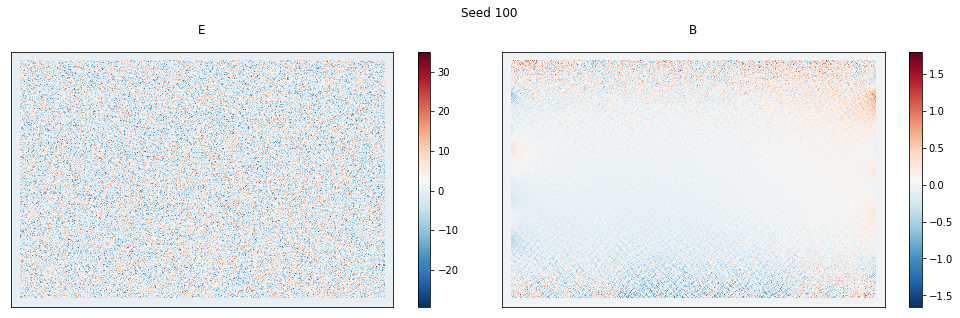

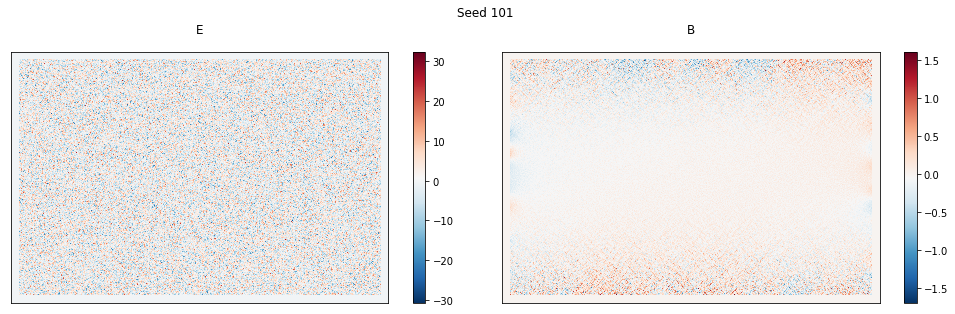

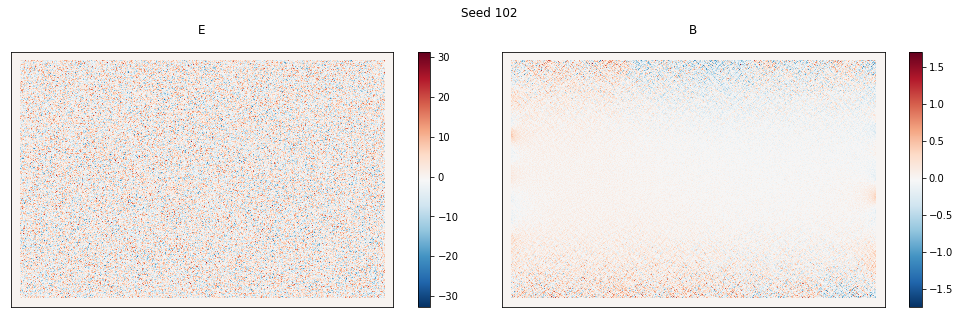

In [30]:
def stream_healpix(seed, keys="TQU"):
    path = "/spt/simulation/lensing_maps/unlensed_TQU1/TQU1_planck2018_base_plikHM_TTTEEE_lowl_lowE_lensing_seed{}.fits"
    for k in keys:
        healpix_map = load_skymap_fits(path.format(seed), memmap=True, keys=k)[k]
        yield (k, healpix_map)

for seed in range(100, 103):
    flatsky_frame   = {k : healpix_to_flatsky(f, map_stub=parent.Clone(False), interp=interp) 
                       for (k, f) in stream_healpix(seed, "QU")};
    
    flattened_frame = {k : f.Clone(True) for (k, f) in flatsky_frame.items()}
    flatten_pol(*flattened_frame.values())
    
    flattened_eb_frame = constructEB(flattened_frame)
    plotFrame(flattened_eb_frame, mult=mask, size=(14,4), suptitle="Seed {}".format(seed))

### Power Spectra

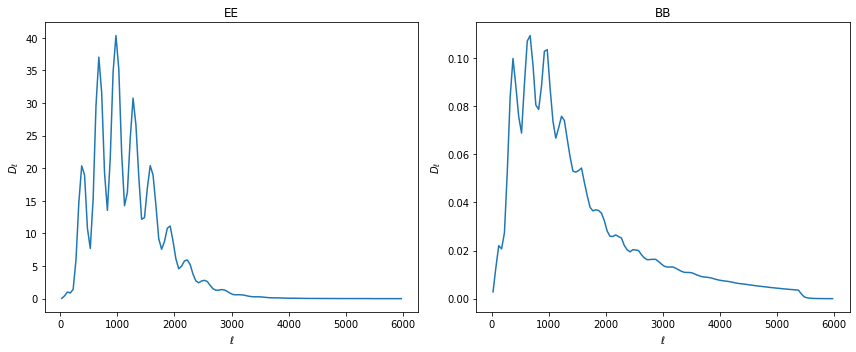

In [32]:
spectra = mapffts_to_powerspectra(flattened_eb_frame, lmax=6000, delta_l=50, calculate_dls=True)
del spectra['EB']
plotFrame(spectra)

## Curved-sky rotation

The polarization rotation angle depends on the derivatives of curved sky coordinates $\delta, \alpha$ with respect to flat-sky coordinates $x,y$, so we need to define a projection before we can do the rotation.

For the sake of computational thrift, we make a mask to select only the Healpix pixels that fall within our flat-sky map.

The derivatives are functions of $x$ and $y$, so we need to calculate those for our Healpix pixels.

In [ ]:
%%time 
(αmin, αmax), (δmin, δmax) = [[f(coord) for f in (np.min, np.max)] for coord in get_ra_dec_map(parent)]
α, δ  = get_ra_dec_map(next(stream_healpix(1))[1])

flatsky_mask = np.array([(αmin < α[i] < αmax) and (δmin < δ[i] < δmax) for i in range(len(α))])
α, δ = (np.asarray(healpix_coord)[flatsky_mask] for healpix_coord in (α, δ))

xy = np.array([parent.angle_to_xy(α[i], δ[i]) for i in range(len(α))])
stub_xy = np.array([parent.angle_to_xy(*parent.pixel_to_angle(i)) for i in range(len(parent))])
xy_mask = np.logical_and.reduce([bool_array 
                                 for bool_set in [(stub_xy[:,i].min() <= xy[:,i], xy[:,i] <= stub_xy[:,i].max()) for i in range(2)] 
                                 for bool_array in bool_set])

### Gradients

In [ ]:
def pixel_scale(xys, map_stub):
    ny, nx = map_stub.shape
    x0, y0 = map_stub.x_center, map_stub.y_center
    x_res, y_res = map_stub.x_res, map_stub.y_res
    
    x_min = (x0 - nx) * x_res
    y_min = (y0 - ny) * y_res
    
    xs = -1. * (xys[:,0] * x_res + x_min);
    ys = -1. * (xys[:,1] * y_res + y_min);
    return xs, ys

def grad_delta(x, y, d0):
    rho = np.sqrt(x**2 + y**2)
    h = np.sqrt(1 - rho**2 / 4)
    g = np.sqrt(1 - rho**2 / 2)

    denominator = rho**2 * h * np.sqrt(1 - (y*h*np.cos(d0) - g**2 * np.sin(d0))**2)
    c = (h**2 - g**2) * y * np.cos(d0) - rho**2 * h * np.sin(d0)
    
    grad_x =  x * c / denominator
    grad_y =   (y * c - (rho*h)**2 * np.cos(d0)) / denominator
    
    return grad_x, grad_y

def grad_alpha(x, y, d0):
    rho = np.sqrt(x**2 + y**2)
    h = np.sqrt(1 - (rho / 2)**2)
    g = np.sqrt(1 - rho**2 / 2)

    denominator = (x * rho * h)**2 + (rho * g**2 * np.cos(d0) + y * rho * h * np.sin(d0))**2
    c = np.cos(d0) * (rho**2 * h + g**4 / h - g**2 * h)
    
    grad_x = (x**2 * c + rho**2 * h * (g**2 * np.cos(d0) + y * h * np.sin(d0))) / denominator
    grad_y = x * (y * c - (rho*h)**2 * np.sin(d0)) / denominator
    
    return grad_x, grad_y

# compute gradients
δ_grd_x, δ_grd_y = grad_delta(*pixel_scale(xy, parent), parent.delta_center)
α_grd_x, α_grd_y = grad_alpha(*pixel_scale(xy, parent), parent.delta_center)

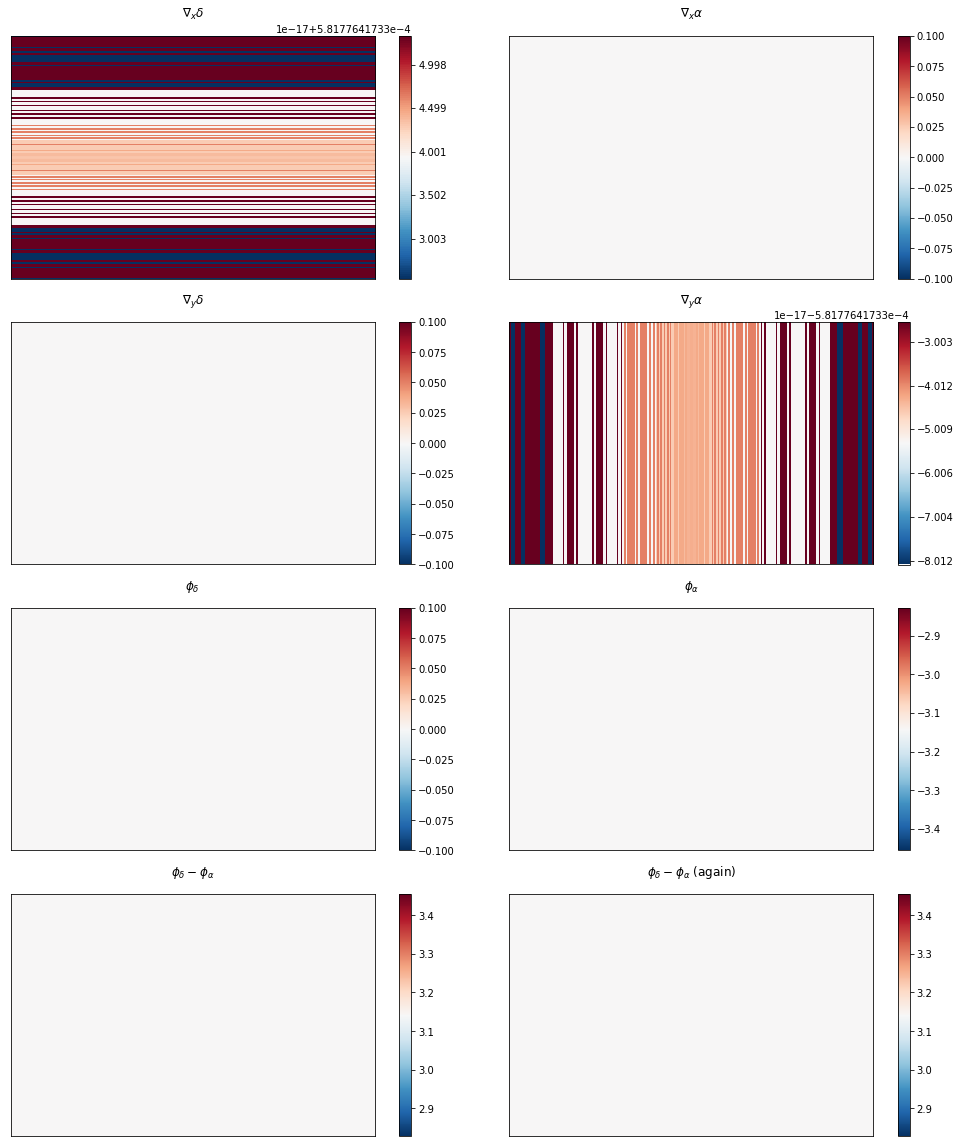

In [33]:
α, δ = get_ra_dec_map(parent)
δ_grd_x, δ_grd_y = np.gradient(δ)
α_grd_x, α_grd_y = np.gradient(α)
grads = {r"$\nabla_x \delta$": δ_grd_x,  r"$\nabla_x \alpha$": α_grd_x, 
         r"$\nabla_y \delta$": δ_grd_y,   r"$\nabla_y \alpha$": α_grd_y,
         r"$\phi_\delta$" : np.arctan2(δ_grd_y, δ_grd_x), r"$\phi_\alpha$" : np.arctan2(-α_grd_x, α_grd_y),
         r"$\phi_\delta - \phi_\alpha$" : np.arctan2(δ_grd_y, δ_grd_x) - np.arctan2(-α_grd_x, α_grd_y),
         r"$\phi_\delta - \phi_\alpha$ (again)" : np.arctan2(δ_grd_y, δ_grd_x) - np.arctan2(-α_grd_x, α_grd_y)}
plotFrame(grads, layout=421, size=(14,16))

Note that in these scatter plots North is up, but in the `FlatSkyMap`s South is up.

In [ ]:
inds = np.random.randint(np.sum(xy_mask), size=20000)
grads = {r"$\nabla_x \delta$": δ_grd_x,  r"$\nabla_x \alpha$": α_grd_x, 
         r"$\nabla_y \delta$": δ_grd_y,   r"$\nabla_y \alpha$": α_grd_y,
         r"$\phi_\delta$" : np.arctan2(δ_grd_y, δ_grd_x), r"$\phi_\alpha$" : np.arctan2(-α_grd_x, α_grd_y),
         r"$\phi_\delta - \phi_\alpha$" : np.arctan2(δ_grd_y, δ_grd_x) - np.arctan2(-α_grd_x, α_grd_y),
         r"$\phi_\delta - \phi_\alpha$ (again)" : np.arctan2(δ_grd_y, δ_grd_x) - np.arctan2(-α_grd_x, α_grd_y)}
fig = figure(figsize=(14, 16), tight_layout=True)
for i, k in enumerate(grads.keys()):
    subplot(421+i)
    scatter(xy[xy_mask][inds, 0], xy[xy_mask][inds, 1], c=grads[k][xy_mask][inds], s=25); 
    title(k); xlabel(r"$x$"); ylabel(r"$y$"); colorbar()
del grads

## Comparison

In [ ]:
phi = np.arctan2(-α_grd_x, α_grd_y) + np.arctan2(δ_grd_y, δ_grd_x)
q, u = [f for (k,f) in stream_healpix(seed, "QU")]
qu = -1*np.exp(1.0j * phi) * (np.asarray(q)[flatsky_mask]  + 1.0j * np.asarray(u)[flatsky_mask])
np.asarray(q)[flatsky_mask] = np.real(qu)
np.asarray(u)[flatsky_mask] = np.imag(qu)

rotated_flatsky_frame = {k : healpix_to_flatsky(f, map_stub=parent.Clone(False), interp=interp)
                         for (k,f) in {'Q' : q, 'U': u}.items()}
del phi, q, u, qu
del δ_grd_x, δ_grd_y, α_grd_x, α_grd_y

### $QU$ $13^\circ$ Insets

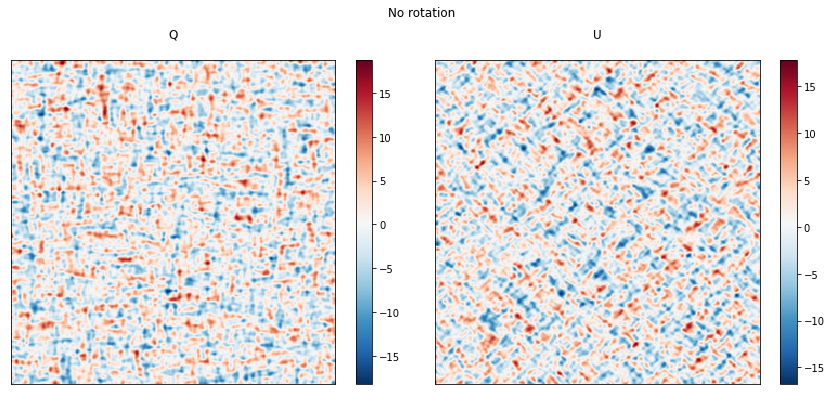

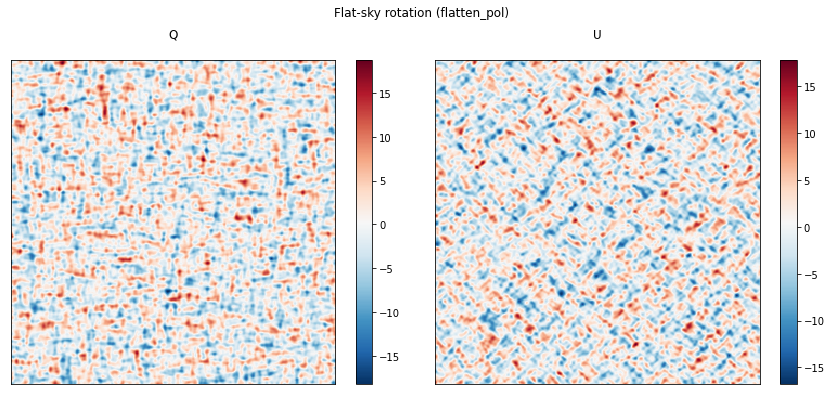

In [35]:
pixmax = 50 + int(300 * 2 / res) # 10 degrees, offset by hard-coded mask width
figsize = (12,5)
plotFrame({k : np.asarray(f)[50:pixmax, 50:pixmax] for (k, f) in flatsky_frame.items()}, suptitle="No rotation", size=figsize)
plotFrame({k : np.asarray(f)[50:pixmax, 50:pixmax] for (k, f) in flattened_frame.items()}, suptitle="Flat-sky rotation (flatten_pol)", size=figsize)
# plotFrame({k : np.asarray(f)[50:pixmax, 50:pixmax] for (k, f) in rotated_flatsky_frame.items()}, suptitle="Curved-sky rotation", size=figsize)
# plotFrame({k : np.asarray(flattened_frame[k] - rotated_flatsky_frame[k])[50:pixmax, 50:pixmax] for k in rotated_flatsky_frame.keys()}, suptitle="Flat-sky - Curved-sky", size=figsize)

### $EB$ Maps

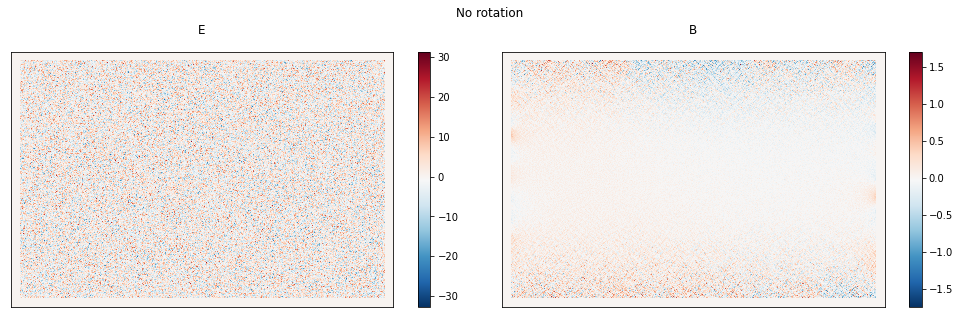

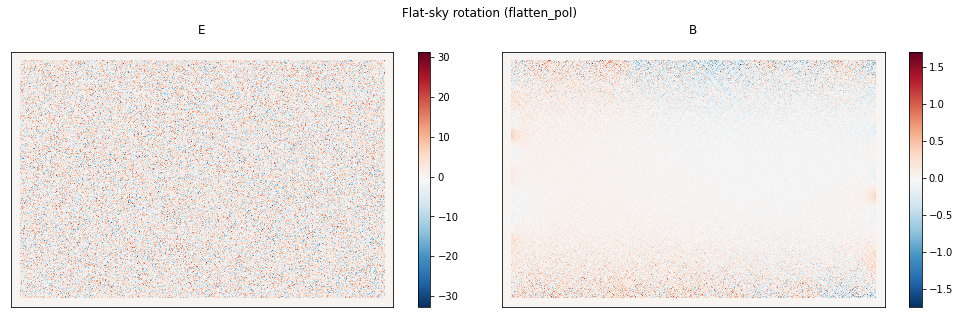

In [36]:
eb_frame = constructEB(flatsky_frame)
rotated_eb_frame = constructEB(rotated_flatsky_frame)


plotFrame(eb_frame, mult=mask, size=(14,4), suptitle="No rotation")
plotFrame(flattened_eb_frame, mult=mask, size=(14,4), suptitle="Flat-sky rotation (flatten_pol)")
plotFrame(rotated_eb_frame, mult=mask, size=(14,4), suptitle="Curved-sky rotation")
plotFrame({k: flattened_eb_frame[k] - rotated_eb_frame[k] for k in eb_frame.keys()}, mult=mask, size=(14,4), suptitle="Flat-sky - Curved-sky")

### $EB\ 13^\circ$ inset

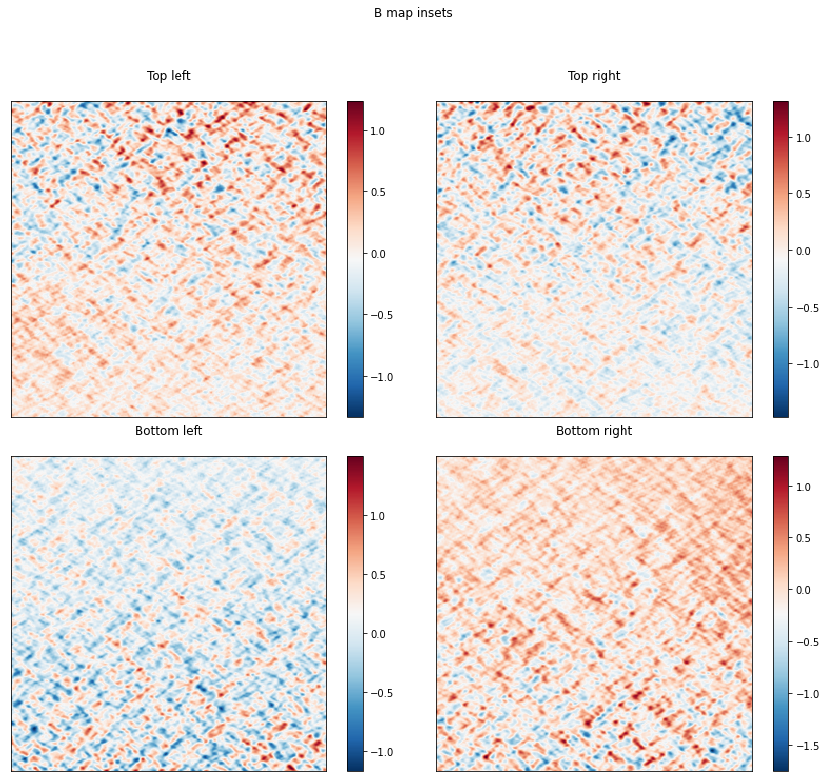

In [37]:
inds = [(50,pixmax), (-pixmax, -50)]
plotFrame(dict(zip(["Top left", "Top right", "Bottom left", "Bottom right"], 
                   [np.asarray(flattened_eb_frame['B'].get_rmap())[inds[i][0]:inds[i][1], inds[k][0]:inds[k][1]] for i in range(2) for k in range(2)])),
          suptitle="B map insets", size=(12,10))

### Power Spectra

In [ ]:
rotated_spectra = mapffts_to_powerspectra(rotated_eb_frame, lmax=6000, delta_l=50, calculate_dls=True)

fig = figure(figsize=(10,4), tight_layout=True)
for i, k in enumerate(['EE', 'BB']):
    subplot(121 + i)
    plot(spectra[k].bin_centers, spectra[k], label="Flat-sky")
    plot(rotated_spectra[k].bin_centers, rotated_spectra[k], label="Curved-sky")
    ylabel(r"${}_\ell$".format(spectra[k].spec_type.upper()[0]))
    xlabel(r"$\ell$") 
    legend()